# 02 · Stockouts and Cold Start: Marking, Not Imputing

M5 has no inventory data, so a zero in the sales record is ambiguous. Treating every zero as "zero demand" teaches models to under-forecast after stockouts. Imputing a demand value invents data. PRISM **marks** suspicious zeros and lets each model handle them in the way that is principled for it:

| Component | How a flagged day is used |
|---|---|
| Kalman filter | treated as a **missing observation**: predict step only, no update (exact for linear-Gaussian models) |
| LightGBM | the row is **dropped from the training loss**; a causal `zero_streak` feature lets the model see an ongoing gap |
| Seasonal naive / TSB | flagged values are skipped when looking up history |
| Evaluation | metrics are reported on **all** target days and on **stockout-masked** target days |

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from prism.config import load_config, resolve, forecast_origins
from prism.data import load_panel
from prism.stockout import flag_stockouts, _zero_runs
from prism.sampling import DEMAND_CLASSES
from prism import plots
plots.apply_style()
FIG = resolve("report/figures")
cfg = load_config()
panel = load_panel(cfg)
m = panel.meta
obs = ~np.isnan(panel.y)
print(f"flagged days: {panel.stockout.sum():,} of {obs.sum():,} observed ({panel.stockout.sum()/obs.sum():.1%})")

flagged days: 296,944 of 2,161,266 observed (13.7%)


## 1. The rule
For a zero-run of length $L$ starting at day $s$, estimate the probability of a zero day from the last $W=56$ observed, unflagged days before $s$ (Laplace-smoothed):
$$\hat\pi_0 = \frac{\#\{\text{zero days}\}+1}{W+2}, \qquad \Pr(L \text{ zeros in a row}) \approx \hat\pi_0^{\,L}.$$
The run is flagged when $\hat\pi_0^{\,L} < p^\* = 10^{-3}$. The rule only looks **backwards** from the run start, so at a forecast origin it can be evaluated on past data only. The one exception is a run still in progress, which is re-judged on its truncated length (`flags_at_cutoff`, unit-tested to equal recomputation from truncated data).

The minimum run length that triggers a flag therefore adapts to each item:

In [2]:
pi0 = np.array([0.05, 0.1, 0.2, 0.4, 0.6, 0.8, 0.9, 0.95])
pd.DataFrame({"P(zero day)": pi0, "min run flagged": np.ceil(np.log(1e-3) / np.log(pi0)).astype(int)}).set_index("P(zero day)").T

P(zero day),0.05,0.10,0.20,0.40,0.60,0.80,0.90,0.95
min run flagged,3,3,5,8,14,31,66,135


## 2. What gets flagged

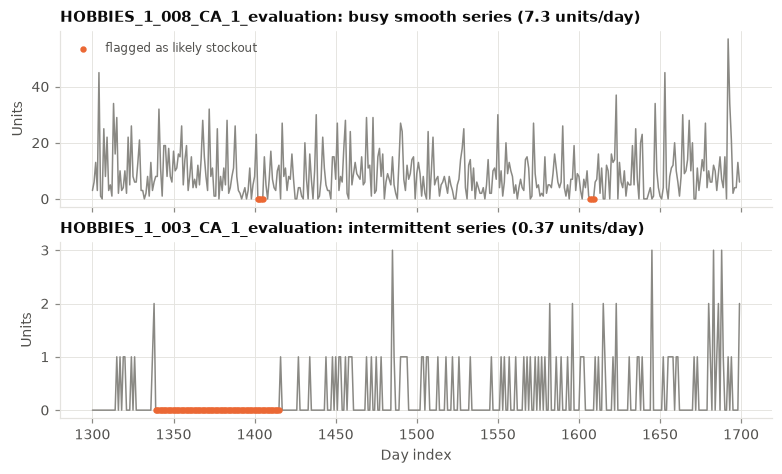

In [3]:
def show(i, lo, hi, ax, title):
    d = np.arange(lo, hi)
    y, f = panel.y[i, lo:hi], panel.stockout[i, lo:hi]
    ax.plot(d, y, color=plots.INK_3, lw=1.0)
    ax.scatter(d[f], y[f], color="#eb6834", s=10, zorder=3, label="flagged as likely stockout")
    ax.set_title(title); ax.set_ylabel("Units")
rate = np.nanmean(panel.y, 1)
frac = panel.stockout.sum(1) / obs.sum(1)
busy = np.flatnonzero((rate > 5) & (frac > 0.02))[0]
inter = np.flatnonzero((m["demand_class"] == "intermittent").to_numpy() & (frac > 0.05))[0]
fig, axes = plt.subplots(2, 1, figsize=(7, 4.2), sharex=True)
show(busy, 1300, 1700, axes[0], f"{m.loc[busy,'id']}: busy smooth series ({rate[busy]:.1f} units/day)")
show(inter, 1300, 1700, axes[1], f"{m.loc[inter,'id']}: intermittent series ({rate[inter]:.2f} units/day)")
axes[0].legend(loc="upper left"); axes[1].set_xlabel("Day index")
plots.save(fig, FIG / "stockout_examples.pdf")

In [4]:
cls = m.assign(flag_share=frac, zero_share=np.nansum(panel.y == 0, 1) / obs.sum(1))
summary = cls.groupby("demand_class")[["zero_share", "flag_share"]].mean()
summary["flagged share of zeros"] = summary["flag_share"] / summary["zero_share"]
summary.round(3)

,zero_share,flag_share,flagged share of zeros
demand_class,,,
erratic,0.180,0.086,0.475
intermittent,0.689,0.173,0.250
lumpy,0.565,0.161,0.284
new,0.391,0.042,0.107
smooth,0.146,0.046,0.317


About 5 % of days are flagged for smooth items and 15–17 % for intermittent/lumpy ones. Even for intermittent items, only about a quarter of the zero days are flagged: the long gaps that their own sales rate cannot explain. Christmas closures are flagged on the busy series.

## 3. Sensitivity to the threshold $p^\*$
The threshold is a modelling choice, so the flagged share is reported across a range of values. The evaluation also always shows *unmasked* metrics, which do not depend on this choice.

,p*,flagged share of observed days
0,0.01000,0.181410
1,0.00100,0.130687
2,0.00010,0.114072
3,0.00001,0.103941


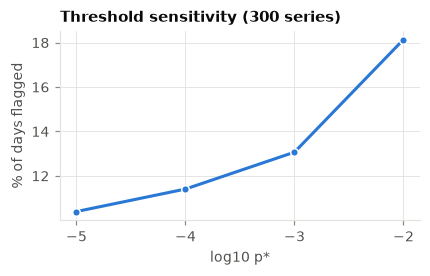

In [5]:
sub = np.random.default_rng(0).choice(panel.n_series, 300, replace=False)
rows = []
for p in [1e-2, 1e-3, 1e-4, 1e-5]:
    f = flag_stockouts(panel.y[sub], p_threshold=p, window=56, min_obs=14)
    rows.append({"p*": p, "flagged share of observed days": f.sum() / obs[sub].sum()})
sens = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(3.8, 2.4))
ax.plot(np.log10(sens["p*"]), sens["flagged share of observed days"] * 100, color="#2a78d6", marker="o", ms=5, mec="white", mew=1)
ax.set_xlabel("log10 p*"); ax.set_ylabel("% of days flagged"); ax.set_title("Threshold sensitivity (300 series)")
ax.set_xticks([-5, -4, -3, -2])
plots.save(fig, FIG / "stockout_sensitivity.pdf")
sens

## 4. Cold start design
Two kinds of new series are evaluated:
* **natural**: series whose first recorded sale is shortly before an origin (rare in M5);
* **simulated**: 10 % of established series (150) have their history before `first_origin − L` hidden, with $L \in \{7, 14, 28, 56\}$ days. Because the backtest rolls forward 28 days at a time, these series are observed with 7…168 days of history across the 5 origins, which traces out a **learning curve**.

A (series, origin) cell counts as *cold start* when it has fewer than 90 days of history. Cells with fewer than 7 days are not scored, since no model can produce a meaningful forecast from them.

In [6]:
origins = forecast_origins(cfg)
H = np.array([[c - l for c in origins] for l in panel.launch])
sim = m["sim_cold_start"].to_numpy()
tab = pd.DataFrame(H[sim], columns=[f"origin {c}" for c in origins])
tab.insert(0, "hidden-history L", origins[0] - panel.launch[sim])
display(tab.groupby("hidden-history L").first())
cold_cells = (H < 90) & (H >= 7)
print("cold-start (series, origin) cells per origin:", dict(zip(origins, cold_cells.sum(0))))

,origin 1801,origin 1829,origin 1857,origin 1885,origin 1913
hidden-history L,,,,,
7,7,35,63,91,119
14,14,42,70,98,126
28,28,56,84,112,140
56,56,84,112,140,168


cold-start (series, origin) cells per origin: {1801: np.int64(150), 1829: np.int64(151), 1857: np.int64(114), 1885: np.int64(3), 1913: np.int64(2)}


**Leakage guard for the simulation:** the hidden history of a simulated series must not come back in through the cross-sectional features. The *item in other stores* and *department in same store* aggregates are computed from the full M5 data **minus the series' own raw sales**, so they contain only other series' information.